# Módulo 1: Fundamentos, Espacios de Color y Mejoramiento Digital

**Objetivo.** Comprender la representación matricial de imágenes $F(x,y) = I$, evaluar la calidad espacial y cuántica, reducir ruido y mejorar el contraste tanto en el dominio espacial como frecuencial.

**Datos.** Se trabaja sobre un frame representativo de un registro del reflejo fotomotor. El video a utilizar se define en `config.py` mediante la variable `VIDEO_PATH`.

## 1.1 Carga, Muestreo y Espacios de Color

Frames totales: 170 | FPS: 30.0 | Duración: 5.7 s


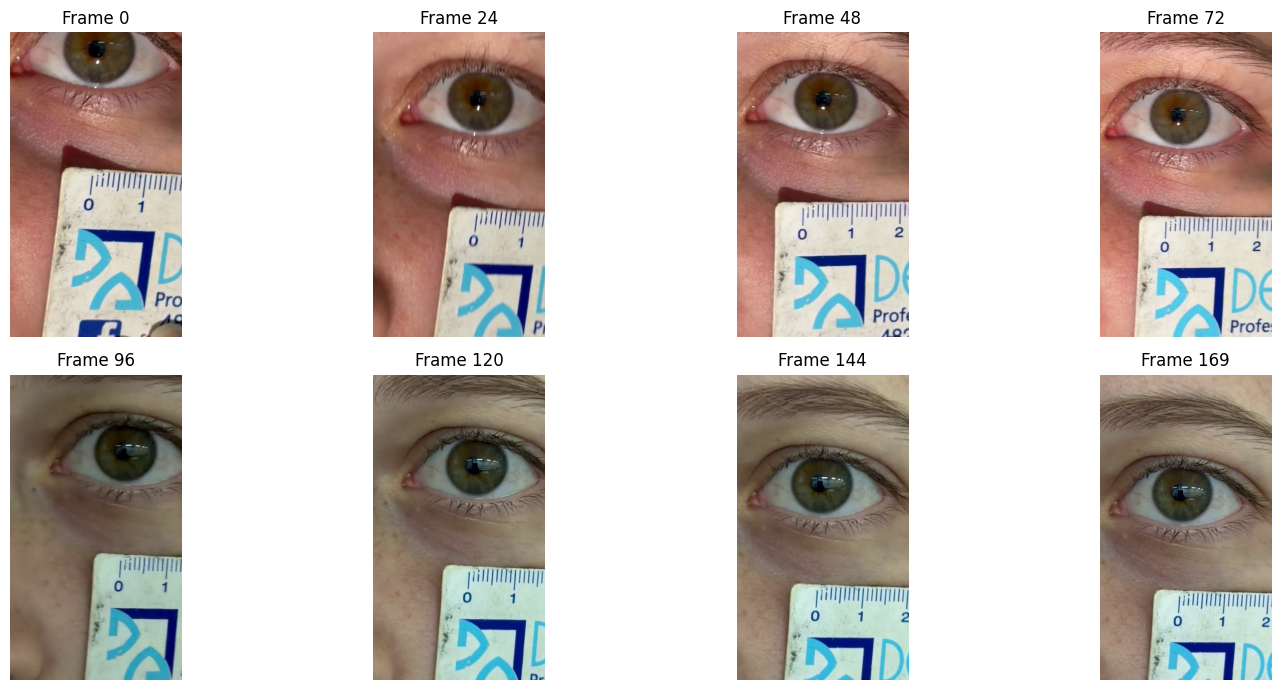

In [1]:
import sys
sys.path.append("..")

import cv2
import matplotlib.pyplot as plt
from config import VIDEO_PATH

cap = cv2.VideoCapture(str(VIDEO_PATH))
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)
print(f"Frames totales: {n_frames} | FPS: {fps:.1f} | Duración: {n_frames/fps:.1f} s")

# 8 frames repartidos a lo largo del video
indices = [int(i * (n_frames - 1) / 7) for i in range(8)]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, idx in zip(axes.flat, indices):
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok, frame = cap.read()
    if ok:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Frame {idx}")
    ax.axis("off")
plt.tight_layout()
plt.show()
cap.release()

### Selección del frame de trabajo y ROI

Se visualizan varios frames distribuidos a lo largo del video para elegir uno representativo: ojo abierto, en foco y con buen contraste entre pupila e iris.

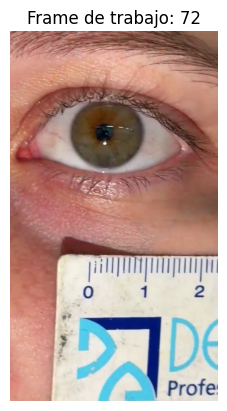

In [2]:
FRAME_IDX = 72  # CAMBIAR CUANDO ELIJAMOS EL VIDEO CORRECTO

cap = cv2.VideoCapture(str(VIDEO_PATH))
cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_IDX)
ok, frame = cap.read()
cap.release()

plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title(f"Frame de trabajo: {FRAME_IDX}")
plt.axis("off")
plt.show()